<a href="https://colab.research.google.com/github/kassingit/IA-EMBARQUEE/blob/main/Lab_session_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab session 3 — Convolutional Neural Networks for Image Classification

> Complete every cell marked with `# ── TODO ──`

In [2]:
# ── Setup ────────────────────────────────────────────────────────────────────
import numpy as np, matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, torch.optim as optim, torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import confusion_matrix
from scipy.signal import convolve2d

torch.manual_seed(42); np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Setup complete! Device: {device}")

Setup complete! Device: cuda


---
## Course Reminders / Tips
- **Convolution:** A kernel slides over the image, computing dot products → feature map.
- **Pooling (MaxPool):** Reduces spatial dims, provides translation invariance.
- **LeNet-5:** `Conv -> Pool -> Conv -> Pool -> Flatten -> Dense -> Dense`.
- **Dropout:** Randomly zeroes neurons during training.
- **Weight Decay (L2):** Adds $\lambda \|W\|^2$ to the loss.

- **Useful links** :
  - Pytorch : https://docs.pytorch.org/docs/2.14/index.html
  - FashionMNIST : https://github.com/zalandoresearch/fashion-mnist
  - Cifar10 : https://cave.cs.toronto.edu/kriz/cifar.html

### Step 1: Manual Convolution (Provided)

100%|██████████| 26.4M/26.4M [00:01<00:00, 19.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 302kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.57MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 24.8MB/s]


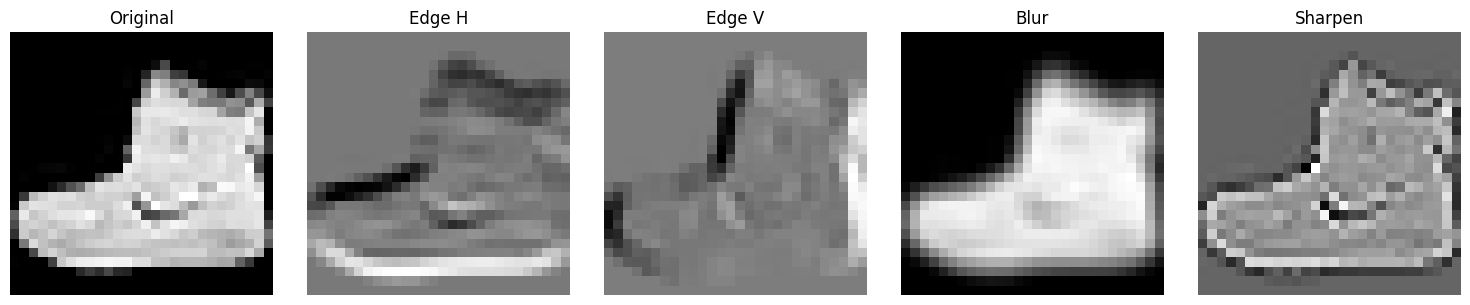

In [3]:
# ── Step 1: Manual Convolution (Provided) ────────────────────────────────────
mnist_data = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transforms.ToTensor())
sample_img = mnist_data[0][0].squeeze().numpy()

kernels = {
    "Edge H": np.array([[-1,-1,-1],[0,0,0],[1,1,1]]),
    "Edge V": np.array([[-1,0,1],[-1,0,1],[-1,0,1]]),
    "Blur":   np.ones((3,3))/9,
    "Sharpen": np.array([[0,-1,0],[-1,5,-1],[0,-1,0]])
}
fig, axes = plt.subplots(1, 5, figsize=(15,3))
axes[0].imshow(sample_img, cmap='gray'); axes[0].set_title("Original")
for i, (name, k) in enumerate(kernels.items()):
    axes[i+1].imshow(convolve2d(sample_img, k, mode='same'), cmap='gray'); axes[i+1].set_title(name)
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

### Step 2: Build a LeNet-like CNN on FashionMNIST

You will compete to build the most performant model using different combinations of layers. Here are some layers you can try :
- Conv2d (number of channel, filter size, stride, padding)
- Dropout
- AvgPool2d/MaxPool2d

To register a score you need to make a small **statistical analysis** of 3 different trainings of your model :
- For each training, note the final  validation accuracy
- Once finished, compute the variance of these 3 runs
- For each training, you need to create a new instance of the model to ensure independance.

In [4]:
# @title
# ── Step 2: CNN on MNIST ───────────────────────────────────────────────
transform_mnist = transforms.Compose([transforms.ToTensor()])
full_train = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform_mnist)
test_ds = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform_mnist)
train_ds, val_ds = random_split(full_train, [54000, 6000])
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=64, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False)

# ── TODO: Modify this CNN architecture to learn the FashionMNIST dataset ───────────────────────────────────────────────
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(in_channels=1, out_channels=4, kernel_size=4,stride = 4)
        # ADDED
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2,2) # 1er
        #self.pool = nn.AvgPool2d(2) # 2e
        self.dropout = nn.Dropout(0.20)
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

        self.fc1_arch2 = nn.Linear(14 * 14 * 32, 128)
        self.fc2_arch2 = nn.Linear(128, 10)

        self.fc1_arch3 = nn.Linear(64 * 3 * 3, 128)
        self.fc2_arch3 = nn.Linear(128, 10)

        #
        self.relu = nn.ReLU()
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(in_features=7*7*4, out_features=10)

    def forward(self, x): # x = (B,1,28,28)
        # 1er Architecture
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)

        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)

        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)


        # 2eme architecture : Faire le pooling une seule fois
        # x = self.conv1(x) # x = (28x28x1) => conv => x = (28x28x16)
        # x = self.relu(x)

        # x = self.conv2(x) # x = (28x28x16) => conv => x = (28x28x32)
        # x = self.relu(x)

        # x = self.pool(x) # x = (28x28x1) => pool => x = (14x14x32)

        # x = self.flatten(x)
        # x = self.fc1_arch2(x)
        # x = self.relu(x)
        # x = self.dropout(x)
        # x = self.fc2_arch2(x)

        # 3eme architecture : Ajouter une 3e couche de convolution
        # x = self.conv1(x)
        # x = self.relu(x)
        # x = self.pool(x)

        # x = self.conv2(x)
        # x = self.relu(x)
        # x = self.pool(x)

        # x = self.conv3(x)
        # x = self.relu(x)
        # x = self.pool(x)

        # x = self.flatten(x)
        # x = self.fc1_arch3(x)
        # x = self.relu(x)
        # x = self.dropout(x)
        # x = self.fc2_arch3(x)
        return x


# ── TODO: Modify these hyperparameters to optimize the training process ───────────────────────────────────────────────
epochs = 3
lr = 0.001
wd = 1e-4
# ─────────────────────────────────────────────────────────────────────────────

In [5]:
# ── Training utility ──────────────────────────────────────────────
def train_model(model, train_loader, val_loader, epochs=10, lr=0.001, wd=0.0):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    history = {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[]}
    for epoch in range(epochs):
        model.train()
        rloss, correct, total = 0, 0, 0

        # Training step
        for imgs, lbls in train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            out = model(imgs)
            loss = criterion(out, lbls)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            rloss += loss.item()*imgs.size(0)
            _, pred = torch.max(out, 1)
            total += lbls.size(0)
            correct += (pred==lbls).sum().item()
        history['train_loss'].append(rloss/total); history['train_acc'].append(correct/total)

        # Validation step
        model.eval()
        vloss, vc, vt = 0, 0, 0
        with torch.no_grad():
            for imgs, lbls in val_loader:
                imgs, lbls = imgs.to(device), lbls.to(device)
                out = model(imgs)
                loss = criterion(out, lbls)
                vloss += loss.item()*imgs.size(0)

                _, pred = torch.max(out, 1)
                vt += lbls.size(0)
                vc += (pred==lbls).sum().item()

        history['val_loss'].append(vloss/vt); history['val_acc'].append(vc/vt)
        print(f"  Epoch {epoch+1}/{epochs} | Train: {history['train_acc'][-1]*100:.1f}% | Val: {history['val_acc'][-1]*100:.1f}%")
    return history

print("Training CNN on FashionMNIST...")
cnn_mnist = CNN()


hist_cnn = train_model(cnn_mnist, train_loader, val_loader, epochs=epochs, lr=lr, wd=wd)

Training CNN on FashionMNIST...
  Epoch 1/3 | Train: 79.9% | Val: 86.8%
  Epoch 2/3 | Train: 87.3% | Val: 88.7%
  Epoch 3/3 | Train: 88.6% | Val: 88.9%


### Step 3: CIFAR-10 with Regularisation (do not use more than 100 000 parameters !)

In [9]:
# ── Step 3: CIFAR-10 CNN ─────────────────────────────────────────────────────
import os
import tarfile

print("Dossier courant :", os.getcwd())
print("Contenu de data :", os.listdir("./data"))
archive = "/cifar-10-python.tar.gz"

with tarfile.open(archive, "r:gz") as tar:
    tar.extractall(path="./data", filter="data")

print(os.listdir("./data/cifar-10-batches-py"))

# Definition de transform_cifar
transform_cifar = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])

cifar_train = datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=transform_cifar
)

cifar_test = datasets.CIFAR10(
    root="./data",
    train=False,
    download=False,
    transform=transform_cifar
)

Dossier courant : /content
Contenu de data : ['FashionMNIST']
['test_batch', 'data_batch_5', 'data_batch_2', 'data_batch_4', 'data_batch_1', 'batches.meta', 'readme.html', 'data_batch_3']


In [11]:
cifar_train = datasets.CIFAR10(root='./data', train=True,  download=True, transform=transform_cifar)
cifar_test  = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_cifar)
cifar_tr, cifar_val = random_split(cifar_train, [45000, 5000])
cifar_train_loader = DataLoader(cifar_tr,  batch_size=64, shuffle=True)
cifar_val_loader   = DataLoader(cifar_val, batch_size=64, shuffle=False)




# ── TODO: Define a 3-block CNN for CIFAR-10 ──────────────────────────────────
# Hint: 3 input channels (RGB!), use Conv2d(3,32,3,padding=1) -> Pool -> Conv2d(32,64,...) -> Pool -> Conv2d(64,128,...) -> Pool
# Add an optional nn.Dropout(0.5) before the final fc layer
class CIFAR_CNN(nn.Module):
    def __init__(self, use_dropout=False):
        super().__init__()
        self.use_dropout = use_dropout

        # Define conv1, conv2, conv3, pool, fc1, fc2, drop
        self.conv1 = nn.Conv2d(3,32,kernel_size=3,padding=1, stride = 1)
        self.conv2 = nn.Conv2d(32,64,kernel_size=3,padding=1, stride = 1)
        self.conv3 = nn.Conv2d(64,128,kernel_size=3,padding=1, stride = 1)

        self.flatten = nn.Flatten()

        self.pool = nn.MaxPool2d(2)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc1 = nn.Linear(128*4*4,64)
        self.fc2 = nn.Linear(64,10)




    def forward(self, x):
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)

        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)

        x = self.conv3(x)
        x = self.relu(x)
        x = self.pool(x)

        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        if self.use_dropout:
          x = self.dropout(x)
        x = self.fc2(x)

        return x
# ─────────────────────────────────────────────────────────────────────────────

def get_model_param(model):
  return sum(p.numel() for p in model.parameters() if p.requires_grad)

if get_model_param(CIFAR_CNN(True)) > 1e6:
  print(f"Model is too big, should be less than 100 000 parameters. Number of parameters in the model : {str(get_model_param(CIFAR_CNN(True)))}")
else:
  print("=== CIFAR-10: No Reg ===")
  hist_noreg = train_model(CIFAR_CNN(False), cifar_train_loader, cifar_val_loader, epochs=10)

  print("\n=== CIFAR-10: Dropout ===")
  hist_drop = train_model(CIFAR_CNN(True), cifar_train_loader, cifar_val_loader, epochs=10)

  print("\n=== CIFAR-10: Weight Decay ===")
  hist_wd = train_model(CIFAR_CNN(False), cifar_train_loader, cifar_val_loader, epochs=10, wd=1e-4)

=== CIFAR-10: No Reg ===
  Epoch 1/10 | Train: 48.8% | Val: 60.2%
  Epoch 2/10 | Train: 64.5% | Val: 65.0%
  Epoch 3/10 | Train: 71.2% | Val: 72.2%
  Epoch 4/10 | Train: 75.2% | Val: 73.4%
  Epoch 5/10 | Train: 78.3% | Val: 74.5%
  Epoch 6/10 | Train: 81.3% | Val: 74.8%
  Epoch 7/10 | Train: 83.6% | Val: 75.6%
  Epoch 8/10 | Train: 85.6% | Val: 75.0%
  Epoch 9/10 | Train: 87.5% | Val: 75.5%
  Epoch 10/10 | Train: 89.0% | Val: 75.4%

=== CIFAR-10: Dropout ===
  Epoch 1/10 | Train: 38.9% | Val: 55.4%
  Epoch 2/10 | Train: 53.6% | Val: 62.8%
  Epoch 3/10 | Train: 59.6% | Val: 68.0%
  Epoch 4/10 | Train: 63.9% | Val: 69.6%
  Epoch 5/10 | Train: 66.7% | Val: 70.8%
  Epoch 6/10 | Train: 69.2% | Val: 73.2%
  Epoch 7/10 | Train: 71.1% | Val: 72.6%
  Epoch 8/10 | Train: 73.3% | Val: 74.2%
  Epoch 9/10 | Train: 74.5% | Val: 74.7%
  Epoch 10/10 | Train: 75.9% | Val: 75.6%

=== CIFAR-10: Weight Decay ===
  Epoch 1/10 | Train: 47.5% | Val: 61.1%
  Epoch 2/10 | Train: 64.4% | Val: 67.1%
  Epoch 3/10

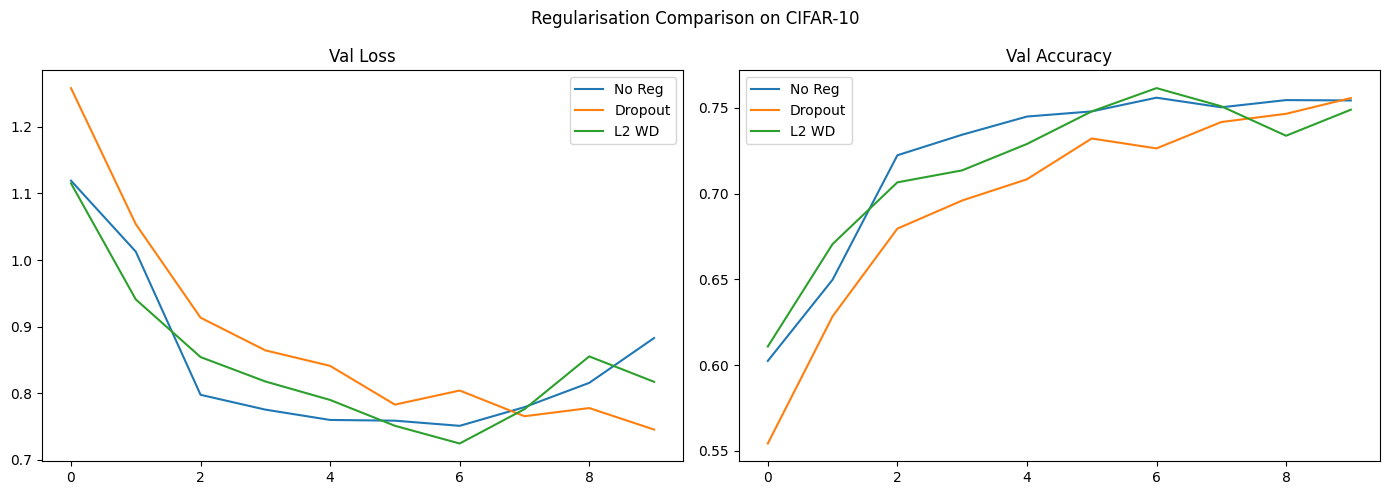

In [12]:
# ── Regularisation Comparison (Provided) ─────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14,5))
for h, lbl in [(hist_noreg,"No Reg"),(hist_drop,"Dropout"),(hist_wd,"L2 WD")]:
    axes[0].plot(h['val_loss'], label=lbl)
    axes[1].plot(h['val_acc'], label=lbl)
axes[0].set_title("Val Loss"); axes[0].legend()
axes[1].set_title("Val Accuracy"); axes[1].legend()
plt.suptitle("Regularisation Comparison on CIFAR-10"); plt.tight_layout(); plt.show()

---
## Summary & Self-Assessment
1. **Why** do CNNs outperform MLPs on image data?
2. **What** does each filter in Conv1 learn to detect?
3. **Regularisation:** Compare Dropout vs L2 Weight Decay on your CIFAR-10 results.

### Next Lab - Implementation of Neural network on an MCU